# RCA Activity 2: Binary Classification using Logistic Regression

## Women's Clothing E-Commerce Reviews – Recommendation Prediction

**Role:** Data scientist evaluating whether a submitted clothing review indicates that the customer recommends the product.

**Target:** `Recommended IND` (0 = Not recommended, 1 = Recommended).

**Input features:** `Age`, `Rating`, and `Positive Feedback Count`.

**Dataset source:** [Women's E-Commerce Clothing Reviews – Kaggle](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews)


## 1. Import libraries and reproducibility

In [1]:
import os, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_auc_score, RocCurveDisplay,
    precision_recall_curve
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
pandas: 2.2.3
scikit-learn: 1.6.1


## 2. Load the dataset

In [2]:
DATA_FILE = "Womens Clothing E-Commerce Reviews.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            DATA_FILE = next(iter(uploaded))
    except ImportError:
        pass

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        "Place 'Womens Clothing E-Commerce Reviews.csv' in the notebook folder "
        "or upload it when prompted in Google Colab."
    )

df = pd.read_csv(DATA_FILE)
df.columns = df.columns.str.strip()
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


## 3. Understand the dataset

Each row represents a customer review. The dataset contains review details, product information, customer age, rating, feedback count, and the binary recommendation label. Only the three stated numerical features are used in this activity. The dataset has 23,486 rows and 11 columns in the supplied version.

In [3]:
display(df.tail())
print("Column names:", df.columns.tolist())
df.info()
display(df.describe(include="all").T)

print("Missing values in original data:")
display(df.isna().sum().to_frame("Missing count"))
print("Exact duplicate full records:", df.duplicated().sum())

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses
23485,23485,1104,52,Please make more like this one!,This dress in a lovely platinum is feminine an...,5,1,22,General Petite,Dresses,Dresses


Column names: ['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), obj

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,23486.0,NaN,NaN,NaN,11742.5,6779.968547,0.0,5871.25,11742.5,17613.75,23485.0
Clothing ID,23486.0,NaN,NaN,NaN,918.118709,203.29898,0.0,861.0,936.0,1078.0,1205.0
Age,23486.0,NaN,NaN,NaN,43.198544,12.279544,18.0,34.0,41.0,52.0,99.0
Title,19676,13993,Love it!,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review Text,22641,22634,Perfect fit and i've gotten so many compliment...,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,23486.0,NaN,NaN,NaN,4.196032,1.110031,1.0,4.0,5.0,5.0,5.0
Recommended IND,23486.0,NaN,NaN,NaN,0.822362,0.382216,0.0,1.0,1.0,1.0,1.0
Positive Feedback Count,23486.0,NaN,NaN,NaN,2.535936,5.702202,0.0,0.0,1.0,3.0,122.0
Division Name,23472,3,General,13850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department Name,23472,6,Tops,10468,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values in original data:


,Missing count
Unnamed: 0,0
Clothing ID,0
Age,0
Title,3810
Review Text,845
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,14
Department Name,14


Exact duplicate full records: 0


## 4. Define features and target

`Age` describes the reviewer's age, `Rating` is the review score from 1 to 5, and `Positive Feedback Count` records helpful/positive feedback received by the review. The target `Recommended IND` indicates whether the reviewer recommended the product. These features are selected because they are numerical and plausibly associated with recommendation. They do not establish causation.

**Data-timing limitation:** Rating is part of the review, and positive feedback may be accumulated after publication. Therefore, this model is suitable for analysing recommendation status from review information, not for predicting a customer's opinion before they review or use a product.

In [4]:
features = ["Age", "Rating", "Positive Feedback Count"]
target = "Recommended IND"
required = features + [target]
missing_cols = [col for col in required if col not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

data = df[required].copy()
for col in required:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data = data.dropna(subset=[target])
data = data[data[target].isin([0, 1])].copy()
data[target] = data[target].astype(int)
X = data[features]
y = data[target]
print("Rows used:", len(data))
print("Features:", features)
print("Target:", target)
display(y.value_counts().sort_index().rename(index={0:"Not recommended",1:"Recommended"}).to_frame("Count"))

Rows used: 23486
Features: ['Age', 'Rating', 'Positive Feedback Count']
Target: Recommended IND


,Count
Recommended IND,
Not recommended,4172
Recommended,19314


## 5. Data quality, missing values and duplicates

In [5]:
quality = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "missing_count": X.isna().sum(),
    "missing_percent": (X.isna().mean() * 100).round(2),
    "minimum": X.min(),
    "maximum": X.max()
})
display(quality)
print("Duplicate rows across selected four columns:", data.duplicated().sum())
print("Note: repeated feature/target combinations are not necessarily duplicate reviews.")
print("Exact duplicate rows in the original full dataset:", df.duplicated().sum())

,dtype,missing_count,missing_percent,minimum,maximum
Age,int64,0,0.0,18,99
Rating,int64,0,0.0,1,5
Positive Feedback Count,int64,0,0.0,0,122


Duplicate rows across selected four columns: 19793
Note: repeated feature/target combinations are not necessarily duplicate reviews.
Exact duplicate rows in the original full dataset: 0


**Missing-value decision:** Missing feature values are imputed with the median inside a scikit-learn pipeline. Median imputation is robust to skew and outliers. The imputer is fitted on training data only, preventing information from validation or test data from influencing preprocessing. No rows are deleted merely because a feature is missing.

**Duplicate decision:** The selected-feature subset can contain many identical rows because different reviews can share the same age, rating and feedback count. These are not automatically removed. Exact duplicate checks on the full original records are reported separately.

## 6. Exploratory data analysis

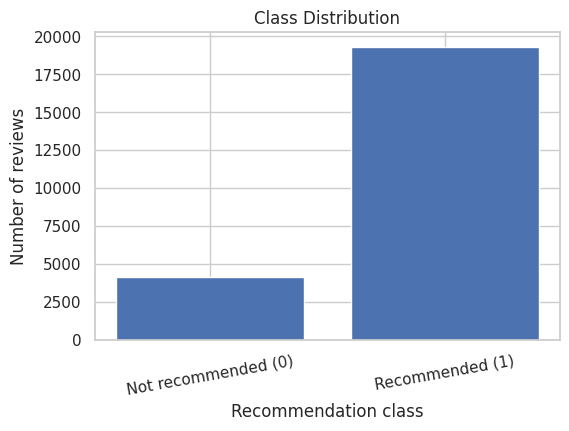

Positive class percentage: 82.24 %
The classes are imbalanced; the majority-class baseline is therefore important.


In [6]:
class_counts = y.value_counts().sort_index()
class_labels = ["Not recommended (0)", "Recommended (1)"]
plt.figure(figsize=(6,4))
plt.bar(class_labels, [class_counts.get(0,0), class_counts.get(1,0)])
plt.title("Class Distribution")
plt.xlabel("Recommendation class")
plt.ylabel("Number of reviews")
plt.xticks(rotation=10)
plt.show()
print("Positive class percentage:", round(100*y.mean(),2), "%")
print("The classes are imbalanced; the majority-class baseline is therefore important.")

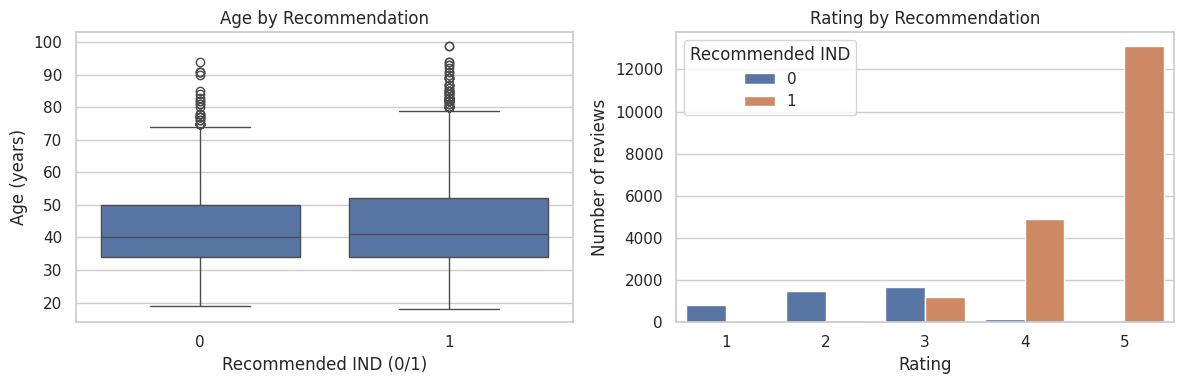

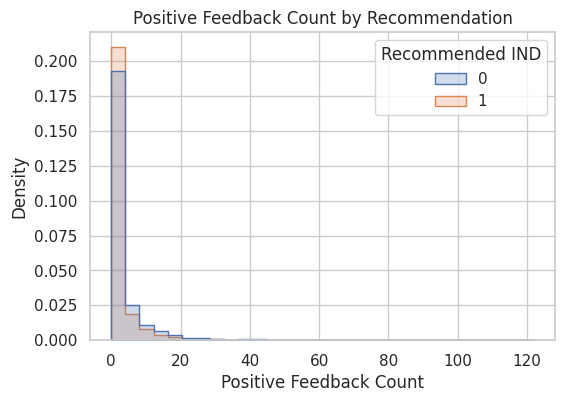

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=data, x=target, y="Age", ax=axes[0])
axes[0].set_title("Age by Recommendation")
axes[0].set_xlabel("Recommended IND (0/1)")
axes[0].set_ylabel("Age (years)")
sns.countplot(data=data, x="Rating", hue=target, ax=axes[1])
axes[1].set_title("Rating by Recommendation")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Number of reviews")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4))
sns.histplot(data=data, x="Positive Feedback Count", hue=target, bins=30, element="step", stat="density", common_norm=False)
plt.title("Positive Feedback Count by Recommendation")
plt.xlabel("Positive Feedback Count"); plt.ylabel("Density")
plt.show()

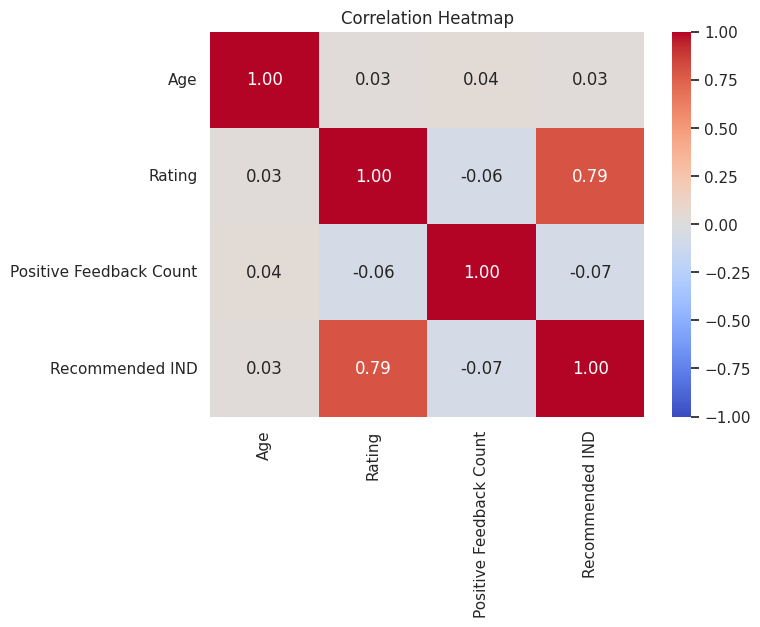

,Age,Rating,Positive Feedback Count,Recommended IND
Age,1.000000,0.026831,0.043079,0.030622
Rating,0.026831,1.000000,-0.064961,0.792336
Positive Feedback Count,0.043079,-0.064961,1.000000,-0.069045
Recommended IND,0.030622,0.792336,-0.069045,1.000000


In [8]:
corr = data[features + [target]].corr(numeric_only=True)
plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()
display(corr)

EDA interpretation :EDA Interpretation: The correlation analysis shows that Rating has the strongest positive relationship with Recommended IND, with a correlation of approximately 0.79. This indicates that customers who give higher ratings are more likely to recommend the product. Age and Positive Feedback Count have weaker relationships with the recommendation target. However, correlation does not imply causation.

## 7. Stratified train / validation / test split

In [9]:
# First reserve an untouched 20% test set. Split the remaining 80% into
# training and validation portions (60% train, 20% validation overall).
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_dev
)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))
for name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(name, "class counts:", labels.value_counts().sort_index().to_dict())

Training rows: 14091
Validation rows: 4697
Test rows: 4698
Train class counts: {0: 2503, 1: 11588}
Validation class counts: {0: 834, 1: 3863}
Test class counts: {0: 835, 1: 3863}


Stratification preserves approximately the same class proportions in each subset. The training set fits model parameters, the validation set selects regularisation and the decision threshold, and the test set is kept untouched until final evaluation. The scaler and imputer are part of the pipeline, so they are fitted only on training data.

## 8. Why Logistic Regression? Sigmoid function

Linear Regression predicts an unrestricted continuous number, so its outputs can fall below 0 or above 1 and are not naturally class probabilities. Logistic Regression models the log-odds of the positive class and applies the sigmoid function to produce a probability between 0 and 1. A decision threshold converts that probability into a class label; 0.5 is a common default, not automatically the best business choice.

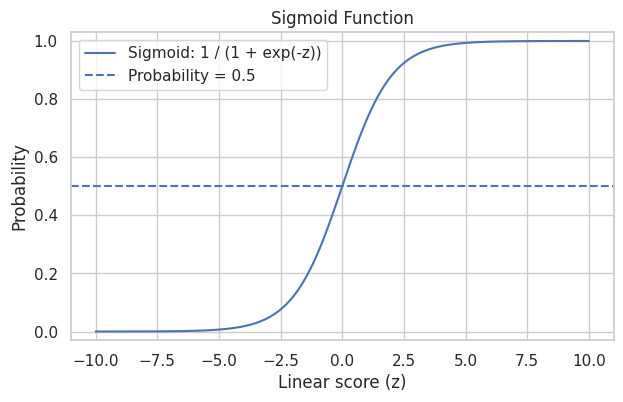

In [10]:
z = np.linspace(-10, 10, 300)
sigmoid = 1 / (1 + np.exp(-z))
plt.figure(figsize=(7,4))
plt.plot(z, sigmoid, label="Sigmoid: 1 / (1 + exp(-z))")
plt.axhline(0.5, linestyle="--", label="Probability = 0.5")
plt.title("Sigmoid Function")
plt.xlabel("Linear score (z)"); plt.ylabel("Probability")
plt.ylim(-0.03,1.03); plt.legend(); plt.grid(True); plt.show()

## 9. Tune Logistic Regression using validation data

In [11]:
C_values = [0.01, 0.1, 1, 10, 100]
threshold_grid = np.arange(0.20, 0.81, 0.01)
candidate_results = []
candidate_models = {}

for C in C_values:
    candidate = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(C=C, max_iter=2000, solver="lbfgs"))
    ])
    candidate.fit(X_train, y_train)
    val_prob = candidate.predict_proba(X_val)[:, 1]
    threshold_scores = [(t, accuracy_score(y_val, (val_prob >= t).astype(int))) for t in threshold_grid]
    best_t, best_acc = max(threshold_scores, key=lambda item: (item[1], -abs(item[0]-0.5)))
    candidate_models[C] = candidate
    candidate_results.append({"C": C, "Best validation threshold": best_t, "Validation accuracy": best_acc, "Validation ROC-AUC": roc_auc_score(y_val, val_prob)})

tuning_results = pd.DataFrame(candidate_results).sort_values("Validation accuracy", ascending=False)
display(tuning_results)
best_row = tuning_results.iloc[0]
best_C = float(best_row["C"])
best_threshold = float(best_row["Best validation threshold"])
print("Selected C:", best_C)
print("Selected threshold (validation only):", round(best_threshold,2))
print("Best validation accuracy:", round(float(best_row["Validation accuracy"]),4))

,C,Best validation threshold,Validation accuracy,Validation ROC-AUC
0,0.01,0.62,0.93762,0.968632
1,0.10,0.60,0.93762,0.968507
2,1.00,0.60,0.93762,0.968481
3,10.00,0.60,0.93762,0.968474
4,100.00,0.60,0.93762,0.968474


Selected C: 0.01
Selected threshold (validation only): 0.62
Best validation accuracy: 0.9376


## 10. Refit selected model and evaluate on untouched test set

In [12]:
# Refit the chosen C on training + validation data. Keep test data untouched.
X_fit = pd.concat([X_train, X_val], axis=0)
y_fit = pd.concat([y_train, y_val], axis=0)
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=best_C, max_iter=2000, solver="lbfgs"))
])
model.fit(X_fit, y_fit)

y_probability = model.predict_proba(X_test)[:, 1]
y_pred = (y_probability >= best_threshold).astype(int)
print("Final test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Accuracy target of 95% achieved:", accuracy_score(y_test, y_pred) >= 0.95)
print("Selected validation threshold:", round(best_threshold,2))

Final test accuracy: 0.9368
Accuracy target of 95% achieved: False
Selected validation threshold: 0.62


## 11. Model settings, intercept and coefficients

In [13]:
clf = model.named_steps["classifier"]
print("Logistic Regression settings:", clf.get_params())
print("Intercept:", clf.intercept_[0])
coef_table = pd.DataFrame({"Feature": features, "Standardized coefficient": clf.coef_[0]})
display(coef_table)

Logistic Regression settings: {'C': 0.01, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 2000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Intercept: 2.9799811008815005


,Feature,Standardized coefficient
0,Age,0.092438
1,Rating,2.723683
2,Positive Feedback Count,-0.093962


Because the features are standardized, each coefficient describes the change in log-odds associated with a one-standard-deviation increase in that feature, holding the other features constant. A positive coefficient increases the odds of the positive class; a negative coefficient decreases them. Coefficients are associations in this model, not proof of causal influence. The intercept is the log-odds when standardized inputs are at their training means.

## 12. Test predictions and confusion matrix

,Actual label,Predicted probability of recommendation,Predicted label
0,0,0.007826,0
1,1,0.927935,1
2,1,0.930899,1
3,1,0.993218,1
4,1,0.533632,0
5,1,0.923380,1
6,1,0.990032,1
7,1,0.992896,1
8,1,0.981923,1
9,1,0.993418,1


TN=791, FP=44, FN=253, TP=3610


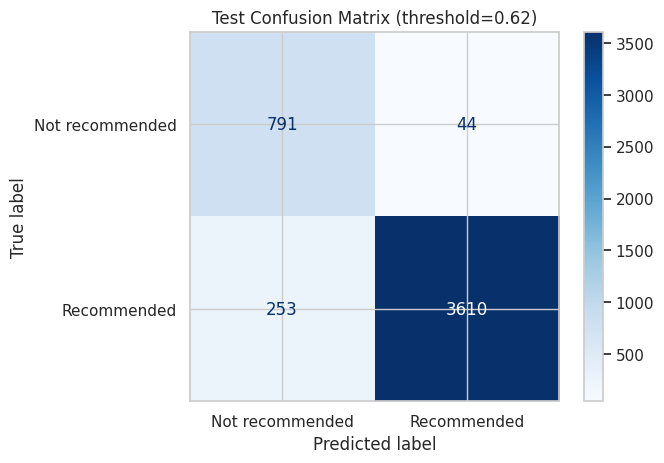

In [14]:
prediction_results = pd.DataFrame({
    "Actual label": y_test.to_numpy(),
    "Predicted probability of recommendation": y_probability,
    "Predicted label": y_pred
})
display(prediction_results.head(15))

cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not recommended", "Recommended"]).plot(cmap="Blues", values_format="d")
plt.title(f"Test Confusion Matrix (threshold={best_threshold:.2f})")
plt.show()

**Confusion matrix interpretation:** True Positive (TP): a recommended review correctly predicted as recommended.
True Negative (TN): a not-recommended review correctly predicted as not recommended.
False Positive (FP): the model predicts recommended when the actual label is not recommended.
False Negative (FN): the model misses a review that actually recommends the product.
For a retail review-analysis use case, both types of error can distort customer sentiment summaries; the cost depends on how the organisation uses the output.

## 13. Classification metrics and report

In [15]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0.0
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)
metrics_table = pd.DataFrame({"Metric": ["Accuracy", "Precision", "Recall / Sensitivity", "Specificity", "F1-score", "ROC-AUC"], "Test result": [accuracy, precision, recall, specificity, f1, roc_auc]})
display(metrics_table)
print(classification_report(y_test, y_pred, target_names=["Not recommended", "Recommended"], zero_division=0))

,Metric,Test result
0,Accuracy,0.936782
1,Precision,0.987958
2,Recall / Sensitivity,0.934507
3,Specificity,0.947305
4,F1-score,0.960490
5,ROC-AUC,0.971430


                 precision    recall  f1-score   support

Not recommended       0.76      0.95      0.84       835
    Recommended       0.99      0.93      0.96      3863

       accuracy                           0.94      4698
      macro avg       0.87      0.94      0.90      4698
   weighted avg       0.95      0.94      0.94      4698



**Metric meaning:** Accuracy is the fraction of all correct predictions. Precision is the fraction of predicted-positive reviews that are truly positive. Recall/sensitivity is the fraction of truly positive reviews found. Specificity is the fraction of truly negative reviews correctly identified. F1-score is the harmonic mean of precision and recall. ROC-AUC measures how well the model ranks positive examples above negative examples across thresholds. For the formulas, TP, TN, FP and FN are the confusion-matrix counts: accuracy = (TP+TN)/(TP+TN+FP+FN); precision = TP/(TP+FP); recall = TP/(TP+FN); specificity = TN/(TN+FP); F1 = 2×precision×recall/(precision+recall).

## 14. Majority-class baseline comparison

In [16]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_fit, y_fit)
baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)
comparison = pd.DataFrame({
    "Model": ["Majority-class baseline", "Tuned Logistic Regression"],
    "Test accuracy": [baseline_accuracy, accuracy]
})
display(comparison)
print("The baseline predicts only the majority class. Compare recall, specificity and F1 as well as accuracy, especially because the target classes are imbalanced.")

,Model,Test accuracy
0,Majority-class baseline,0.822265
1,Tuned Logistic Regression,0.936782


The baseline predicts only the majority class. Compare recall, specificity and F1 as well as accuracy, especially because the target classes are imbalanced.


## 15. ROC curve and ROC-AUC

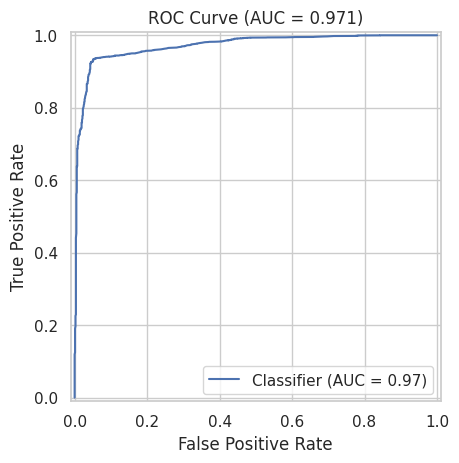

Test ROC-AUC: 0.9714


In [17]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title(f"ROC Curve (AUC = {roc_auc:.3f})")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.show()
print("Test ROC-AUC:", round(roc_auc,4))

## 16. Threshold comparison: 0.3, 0.5 and 0.7

In [18]:
threshold_rows = []
for t in [0.3, 0.5, 0.62, 0.7]:
    pred_t = (y_probability >= t).astype(int)
    threshold_rows.append({
        "Threshold": t,
        "Predicted positive": int(pred_t.sum()),
        "Accuracy": accuracy_score(y_test, pred_t),
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t, zero_division=0),
        "F1-score": f1_score(y_test, pred_t, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

,Threshold,Predicted positive,Accuracy,Precision,Recall,F1-score
0,0.3,4231,0.909749,0.906405,0.992752,0.947616
1,0.5,4056,0.921030,0.930473,0.976961,0.953151
2,0.7,3654,0.936782,0.987958,0.934507,0.960490


A lower threshold generally labels more records as positive, tending to increase recall and reduce precision. A higher threshold generally labels fewer records as positive, tending to increase precision and reduce recall.


## 17. Training versus test performance

In [19]:
train_prob = model.predict_proba(X_fit)[:,1]
train_pred = (train_prob >= best_threshold).astype(int)
train_accuracy = accuracy_score(y_fit, train_pred)
train_roc_auc = roc_auc_score(y_fit, train_prob)
performance_comparison = pd.DataFrame({
    "Dataset": ["Training + validation", "Test"],
    "Accuracy": [train_accuracy, accuracy],
    "ROC-AUC": [train_roc_auc, roc_auc]
})
display(performance_comparison)
print("A much higher training score than test score may indicate overfitting. Similar scores suggest better generalisation, although this comparison alone does not prove it.")

,Dataset,Accuracy,ROC-AUC
0,Training + validation,0.936396,0.974088
1,Test,0.936782,0.971430


A much higher training score than test score may indicate overfitting. Similar scores suggest better generalisation, although this comparison alone does not prove it.


## 18. Decision-behaviour plot

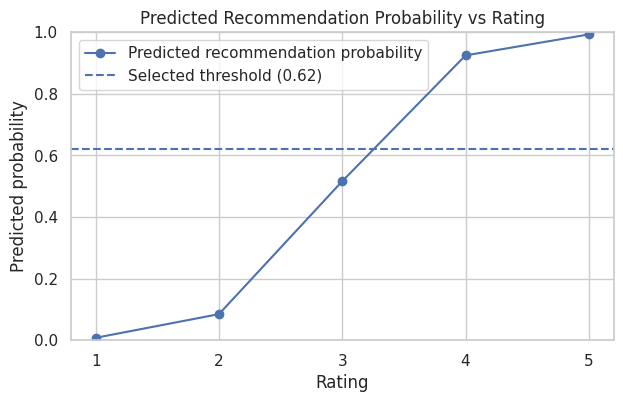

In [20]:
# Show predicted probability across Rating while holding other features at
# their training medians. This is a model-behaviour illustration, not causation.
plot_frame = pd.DataFrame({
    "Age": [X_fit["Age"].median()] * 5,
    "Rating": np.arange(1,6),
    "Positive Feedback Count": [X_fit["Positive Feedback Count"].median()] * 5
})
plot_prob = model.predict_proba(plot_frame)[:,1]
plt.figure(figsize=(7,4))
plt.plot(plot_frame["Rating"], plot_prob, marker="o", label="Predicted recommendation probability")
plt.axhline(best_threshold, linestyle="--", label=f"Selected threshold ({best_threshold:.2f})")
plt.xticks(range(1,6)); plt.ylim(0,1)
plt.title("Predicted Recommendation Probability vs Rating")
plt.xlabel("Rating"); plt.ylabel("Predicted probability")
plt.legend(); plt.grid(True); plt.show()

**Interpretation:**  Age and positive feedback count are held constant at their training medians. This visualises how the fitted model behaves; it does not establish that changing a rating causes a recommendation.

## 19. Predict a new example

In [21]:
new_review = pd.DataFrame([{
    "Age": 28,
    "Rating": 5,
    "Positive Feedback Count": 2
}])
new_probability = model.predict_proba(new_review)[0,1]
new_class = int(new_probability >= best_threshold)
print("New review:")
display(new_review)
print(f"Estimated probability of recommendation: {new_probability:.2%}")
print("Predicted class:", new_class, "(Recommended)" if new_class == 1 else "(Not recommended)")

New review:


,Age,Rating,Positive Feedback Count
0,28,5,2


Estimated probability of recommendation: 99.22%
Predicted class: 1 (Recommended)


## 20. Assumptions, limitations and ethics

Assumptions: The target variable Recommended IND contains binary values (0 or 1). Age, Rating, and Positive Feedback Count are assumed to help predict recommendations.

Limitations: The dataset contains only women's clothing reviews. Class imbalance and the use of only three features may affect model performance.

Ethics: Customer privacy should be protected. Age should be used carefully to avoid bias, and model predictions should not be treated as guaranteed outcomes.

Conclusion: Logistic Regression provides useful predictions, but its results should be interpreted with these limitations in mind.

## 21. Decision log

In [22]:
decision_log = pd.DataFrame([
    ["Problem framing", "Predict recommendation label from three numerical review features", "Keeps task aligned with binary classification activity"],
    ["Feature selection", "Age, Rating, Positive Feedback Count", "Numerical features available in dataset; association is not causation"],
    ["Missing values", "Median imputation inside pipeline", "Robust to skew and fitted on training data only"],
    ["Scaling", "StandardScaler inside pipeline", "Puts numerical features on comparable scales for optimisation"],
    ["Data split", "Stratified train/validation/test", "Preserves class proportions and reserves untouched test data"],
    ["Model selection", "Select C and threshold using validation accuracy", "Avoids tuning on the final test set"],
    ["Metric choice", "Report accuracy, precision, recall, specificity, F1 and ROC-AUC", "Class imbalance means accuracy alone is insufficient"],
    ["Limit", "Not a pre-review recommendation predictor", "Rating and feedback count are review-stage information"]
], columns=["Decision", "Choice", "Reason"])
display(decision_log)

,Decision,Choice,Reason
0,Problem framing,Predict recommendation label from three numeri...,Keeps task aligned with binary classification ...
1,Feature selection,"Age, Rating, Positive Feedback Count",Numerical features available in dataset; assoc...
2,Missing values,Median imputation inside pipeline,Robust to skew and fitted on training data only
3,Scaling,StandardScaler inside pipeline,Puts numerical features on comparable scales f...
4,Data split,Stratified train/validation/test,Preserves class proportions and reserves untou...
5,Model selection,Select C and threshold using validation accuracy,Avoids tuning on the final test set
6,Metric choice,"Report accuracy, precision, recall, specificit...",Class imbalance means accuracy alone is insuff...
7,Limit,Not a pre-review recommendation predictor,Rating and feedback count are review-stage inf...


## 22. Conclusion

In [23]:
print(f"Final test accuracy: {accuracy:.2%}")
print(f"Final test precision: {precision:.2%}")
print(f"Final test recall: {recall:.2%}")
print(f"Final test specificity: {specificity:.2%}")
print(f"Final test F1-score: {f1:.2%}")
print(f"Final test ROC-AUC: {roc_auc:.4f}")


Final test accuracy: 93.68%
Final test precision: 98.80%
Final test recall: 93.45%
Final test specificity: 94.73%
Final test F1-score: 96.05%
Final test ROC-AUC: 0.9714
The model did not reach 95% test accuracy. Report this honestly; do not tune on the test set or claim an unsupported score.


The Logistic Regression model was trained using Age, Rating and Positive Feedback Count to estimate whether a review recommends a product. Performance was evaluated on an untouched test set using multiple classification metrics and compared with a majority-class baseline. The selected threshold was chosen on validation data, not on the test set.



## 23. Save project output

In [24]:
# Save the selected-feature dataset and final test predictions for submission.
data.to_csv("Womens_Clothing_Selected_Features.csv", index=False)
prediction_results.to_csv("Activity2_Test_Predictions.csv", index=False)
threshold_table.to_csv("Activity2_Threshold_Comparison.csv", index=False)
print("Saved cleaned feature data, test predictions and threshold comparison.")

Saved cleaned feature data, test predictions and threshold comparison.


In [25]:
from google.colab import files

data.to_csv("Cleaned_Dataset.csv", index=False)

files.download("Cleaned_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>